In [12]:
import polars as pl
import matplotlib.pyplot as plt
import numpy as np

In [13]:

# read data from dataset/raw/Acacia confusa/
df_C = pl.read_csv("../../dataset/raw/Acacia confusa/20250923-Acacia confusa-1-C-1.txt", separator=";", has_header=False)
df_R = pl.read_csv("../../dataset/raw/Acacia confusa/20250923-Acacia confusa-1-R-1.txt", separator=";", has_header=False)
df_T = pl.read_csv("../../dataset/raw/Acacia confusa/20250923-Acacia confusa-1-T-1.txt", separator=";", has_header=False)

In [14]:
# Process each dataframe (clean and rename columns)
def process_raman_data(df: pl.DataFrame, facet_name: str) -> pl.DataFrame:
    """Process Raman spectral data and baseline-correct negative intensities"""

    # Drop third column (all zeros) and rename
    df_processed = df.drop("column_3").rename({
        "column_1": "wavenumber",
        "column_2": "intensity"
    })

    # Compute intensity minimum once
    intensity_min = df_processed["intensity"].min()

    # Add facet identifier and baseline-shifted intensity
    df_processed = df_processed.with_columns([
        pl.when(intensity_min < 0)
          .then(pl.col("intensity") - intensity_min)
          .otherwise(pl.col("intensity"))
          .alias("intensity_shifted"),
        pl.lit(facet_name).alias("facet")
    ])
    return df_processed

# Process all three facets
df_C_processed = process_raman_data(df_C, "Cross")
df_R_processed = process_raman_data(df_R, "Radial")
df_T_processed = process_raman_data(df_T, "Tangential")

In [15]:
df_C_processed

wavenumber,intensity,intensity_shifted,facet
f64,f64,f64,str
98.64605,0.0,867.702942,"""Cross"""
101.2353,0.0,867.702942,"""Cross"""
103.8217,0.0,867.702942,"""Cross"""
106.4096,13.755555,881.458497,"""Cross"""
108.9945,-9.306666,858.396276,"""Cross"""
…,…,…,…
3505.699,-33.37537,834.327572,"""Cross"""
3506.716,30.846828,898.54977,"""Cross"""
3507.729,-38.478634,829.224308,"""Cross"""


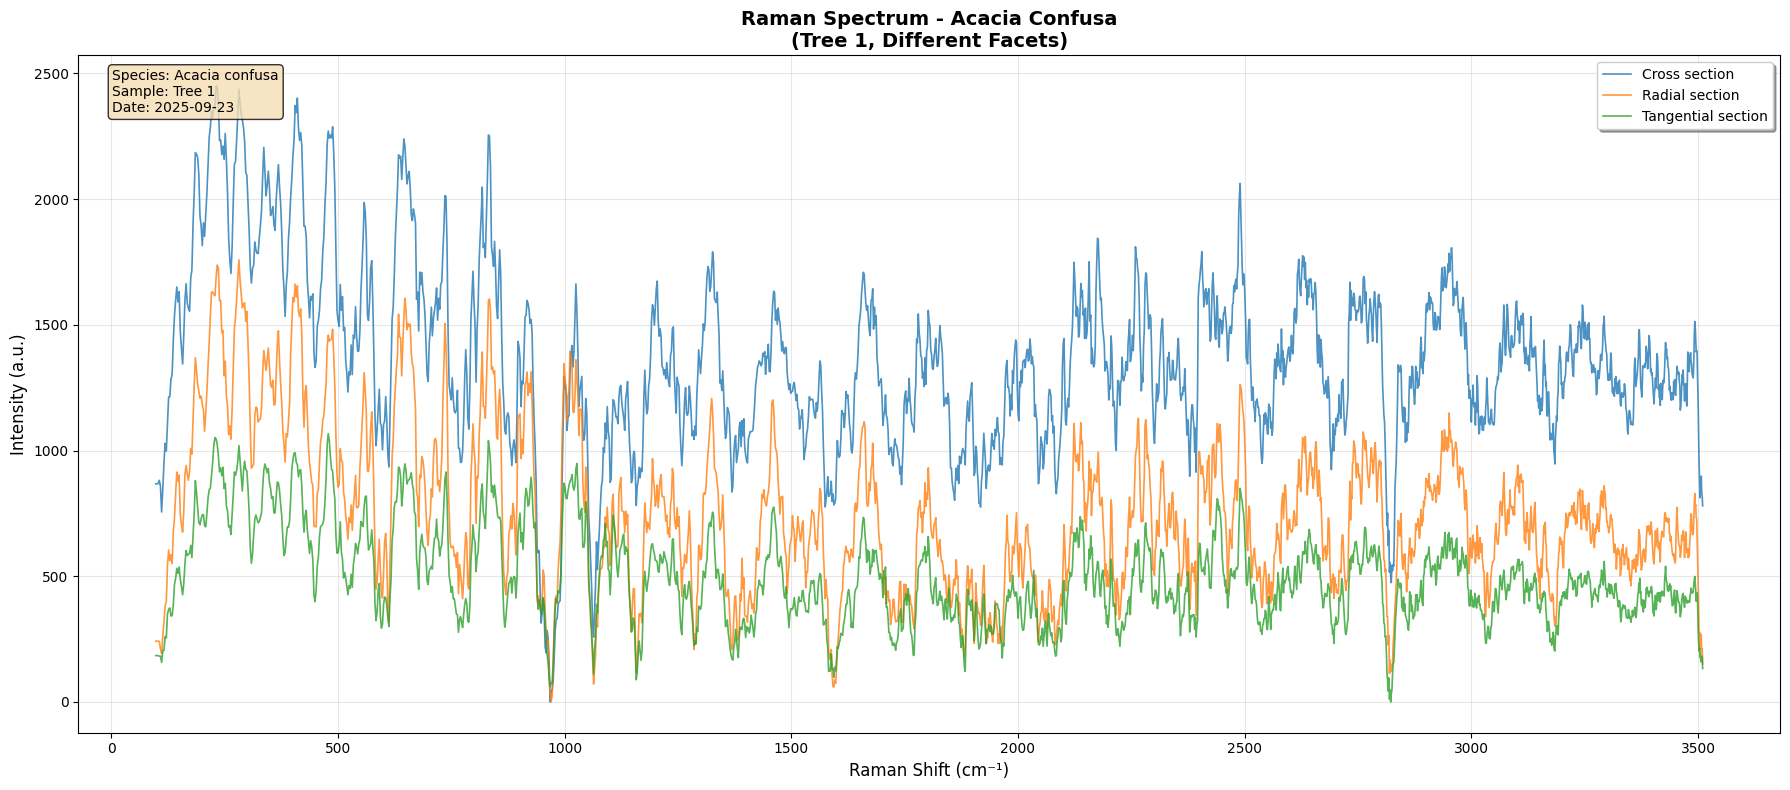

In [20]:
# Create publication-quality Raman spectrum plot
plt.figure(figsize=(18, 8))

# Plot all three facets
plt.plot(df_C_processed["wavenumber"], df_C_processed["intensity_shifted"],
         label="Cross section", color='#1f77b4', linewidth=1.2, alpha=0.8)
plt.plot(df_R_processed["wavenumber"], df_R_processed["intensity_shifted"],
         label="Radial section", color='#ff7f0e', linewidth=1.2, alpha=0.8)
plt.plot(df_T_processed["wavenumber"], df_T_processed["intensity_shifted"],
         label="Tangential section", color='#2ca02c', linewidth=1.2, alpha=0.8)

# Format plot with spectroscopy standards
plt.xlabel('Raman Shift (cm⁻¹)', fontsize=12)
plt.ylabel('Intensity (a.u.)', fontsize=12)
plt.title('Raman Spectrum - Acacia Confusa\n(Tree 1, Different Facets)', fontsize=14, fontweight='bold')
plt.legend(frameon=True, fancybox=True, shadow=True)
plt.grid(True, alpha=0.3)

# # Invert x-axis (spectroscopy convention)
# plt.gca().invert_xaxis()

# Add sample information
plt.text(0.02, 0.98, 'Species: Acacia confusa\nSample: Tree 1\nDate: 2025-09-23',
         transform=plt.gca().transAxes, verticalalignment='top',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.8))

plt.tight_layout()
plt.show()

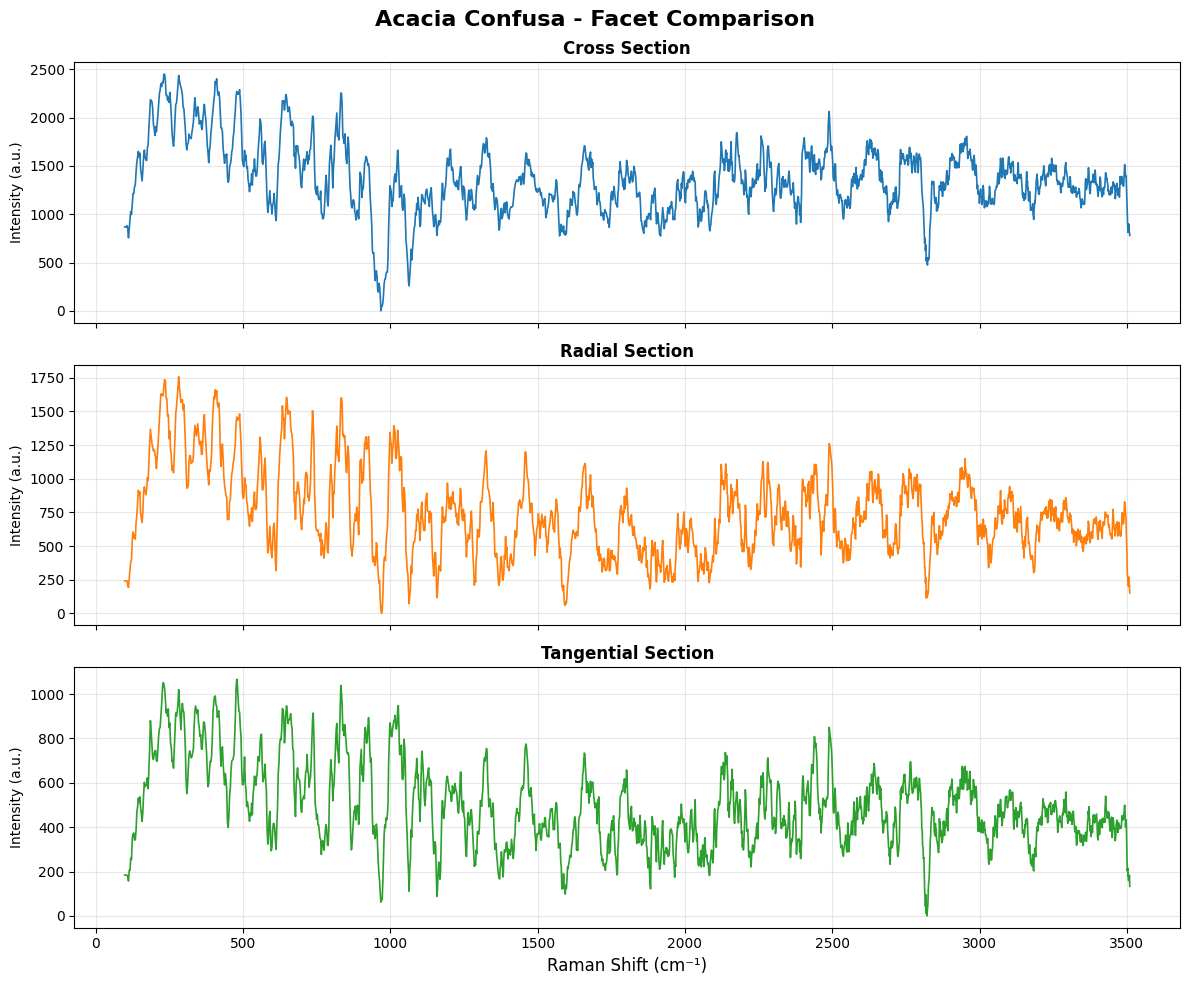

In [23]:
# Individual subplot view for detailed comparison
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)

# Plot each facet in separate subplot
facets_data = [
    (df_C_processed, "Cross Section", '#1f77b4'),
    (df_R_processed, "Radial Section", '#ff7f0e'),
    (df_T_processed, "Tangential Section", '#2ca02c')
]

for i, (df, title, color) in enumerate(facets_data):
    axes[i].plot(df["wavenumber"], df["intensity_shifted"],
                label=f"Facet {i+1}",
                color=color, linewidth=1.2)
    axes[i].set_title(title, fontweight='bold')
    axes[i].set_ylabel('Intensity (a.u.)')
    axes[i].grid(True, alpha=0.3)
    # axes[i].invert_xaxis()

axes[2].set_xlabel('Raman Shift (cm⁻¹)', fontsize=12)
plt.suptitle('Acacia Confusa - Facet Comparison', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

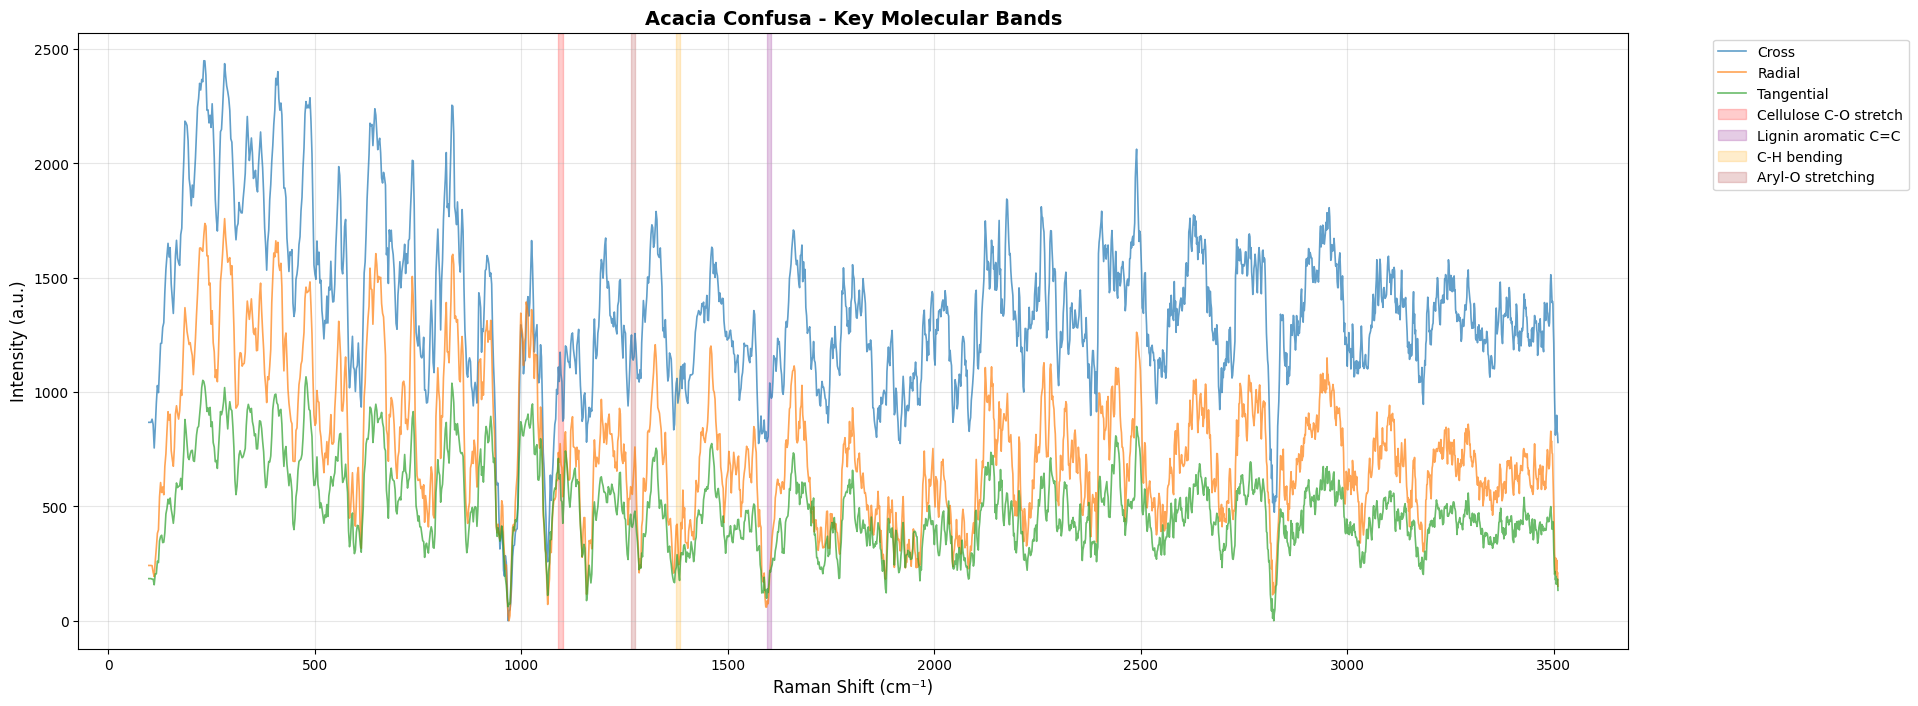

=== Raman Spectral Data Summary ===

Cross Facet:
  Wavenumber range: 98.6 - 3509.8 cm⁻¹
  Intensity range: -867.7 - 1581.6
  Mean intensity: 478.0
  Data points: 2005

Radial Facet:
  Wavenumber range: 98.6 - 3509.8 cm⁻¹
  Intensity range: -241.7 - 1516.9
  Mean intensity: 481.9
  Data points: 2005

Tangential Facet:
  Wavenumber range: 98.6 - 3509.8 cm⁻¹
  Intensity range: -184.2 - 882.7
  Mean intensity: 294.1
  Data points: 2005


In [25]:
# Highlight key molecular regions for wood analysis
plt.figure(figsize=(20, 8))

# Plot all spectra
plt.plot(df_C_processed["wavenumber"], df_C_processed["intensity_shifted"],
         label="Cross", alpha=0.7, linewidth=1.2)
plt.plot(df_R_processed["wavenumber"], df_R_processed["intensity_shifted"],
         label="Radial", alpha=0.7, linewidth=1.2)
plt.plot(df_T_processed["wavenumber"], df_T_processed["intensity_shifted"],
         label="Tangential", alpha=0.7, linewidth=1.2)

# Highlight important molecular bands for wood identification
molecular_bands = {
    'Cellulose C-O stretch': (1090, 1100),
    'Lignin aromatic C=C': (1595, 1605),
    'C-H bending': (1375, 1385),
    'Aryl-O stretching': (1265, 1275)
}

colors = ['red', 'purple', 'orange', 'brown']
for i, (band_name, (low, high)) in enumerate(molecular_bands.items()):
    plt.axvspan(low, high, alpha=0.2, color=colors[i], label=band_name)

plt.xlabel('Raman Shift (cm⁻¹)', fontsize=12)
plt.ylabel('Intensity (a.u.)', fontsize=12)
plt.title('Acacia Confusa - Key Molecular Bands', fontsize=14, fontweight='bold')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
# plt.gca().invert_xaxis()
# plt.tight_layout()
plt.show()

# Data summary statistics
print("=== Raman Spectral Data Summary ===")
for name, df in [("Cross", df_C_processed), ("Radial", df_R_processed), ("Tangential", df_T_processed)]:
    print(f"\n{name} Facet:")
    print(f"  Wavenumber range: {df['wavenumber'].min():.1f} - {df['wavenumber'].max():.1f} cm⁻¹")
    print(f"  Intensity range: {df['intensity'].min():.1f} - {df['intensity'].max():.1f}")
    print(f"  Mean intensity: {df['intensity'].mean():.1f}")
    print(f"  Data points: {len(df)}")

In [19]:
# Combine all data for further analysis
df_combined = pl.concat([df_C_processed, df_R_processed, df_T_processed])
print(f"\nCombined dataset shape: {df_combined.shape}")
print(f"Facets: {df_combined['facet'].unique().to_list()}")


Combined dataset shape: (6015, 4)
Facets: ['Tangential', 'Radial', 'Cross']


In [32]:
exec(open("../../src/reorganize_dataset.py").read())


Processing Chamaecyparis obyusa...
Processing Swietenia mahagoni...
Processing Swietenia marophylla...
Processing Machilus kusanoi...
Processing Acacia confusa...
Processing Chamaecyparis formosensis...
Processing Acacia mangium...
Processing Chamaecyparis obtusa var. formosana...
Processing Fokienia hodginsii...
Dataset reorganization completed!
Generated metadata for 960 files
Species processed: ['Acacia_Confusa', 'Acacia_Mangium', 'Chamaecyparis_Formosensis', 'Chamaecyparis_Obtusa_var_Formosana', 'Chamaecyparis_Obyusa', 'Fokienia_Hodginsii', 'Machilus_Kusanoi', 'Swietenia_Mahagoni', 'Swietenia_Marophylla']
Trees: 24
Cubes: 31

=== Dataset Reorganization Summary ===
Total files processed: 960
Training files: 840
Test files: 120
Species: 9
Unique trees: 24
Unique cubes: 31


In [33]:
exec(open("../../src/fix_name_rule.py").read())


🔄 Fixing Chamaecyparis_Obyusa...
✅ Fixed 90 files for Chamaecyparis_Obyusa
✅ Skipping Swietenia_Marophylla (already correct)
🔄 Fixing Acacia_Mangium...
✅ Fixed 60 files for Acacia_Mangium
🔄 Fixing Chamaecyparis_Formosensis...
✅ Fixed 60 files for Chamaecyparis_Formosensis
🔄 Fixing Acacia_Confusa...
✅ Fixed 60 files for Acacia_Confusa
🔄 Fixing Swietenia_Mahagoni...
✅ Fixed 90 files for Swietenia_Mahagoni
🔄 Fixing Machilus_Kusanoi...
✅ Fixed 60 files for Machilus_Kusanoi
🔄 Fixing Fokienia_Hodginsii...
✅ Fixed 45 files for Fokienia_Hodginsii
✅ Skipping Chamaecyparis_Obtusa_var_Formosana (already correct)

🎉 Filename convention fix completed!

=== Verification Results ===
Chamaecyparis_Obyusa: ['1-1', '1-2', '1-3', '1-4']
Swietenia_Marophylla: ['1-1', '1-2', '1-3']
Acacia_Mangium: ['1-1', '1-2', '1-3']
Chamaecyparis_Formosensis: ['1-1', '1-2', '1-3']
Acacia_Confusa: ['1-1', '1-2', '1-3']
Swietenia_Mahagoni: ['1-2', '1-3', '1-4']
Machilus_Kusanoi: ['1-1', '1-2', '1-3']
Fokienia_Hodginsii: [

In [35]:
exec(open("../../src/clean_organized_dataset.py").read())

=== BEFORE CLEANING ===

📄 Sample file: 100mW-20250922-Chamaecyparis_Obyusa-1-2-R-10.txt
Shape: (2005, 3)
Columns: ['column_1', 'column_2', 'column_3']
First 5 rows:
shape: (5, 3)
┌──────────┬────────────┬──────────┐
│ column_1 ┆ column_2   ┆ column_3 │
│ ---      ┆ ---        ┆ ---      │
│ f64      ┆ f64        ┆ i64      │
╞══════════╪════════════╪══════════╡
│ 98.64605 ┆ 0.0        ┆ 0        │
│ 101.2353 ┆ 0.0        ┆ 0        │
│ 103.8217 ┆ 0.0        ┆ 0        │
│ 106.4096 ┆ 9.551481   ┆ 0        │
│ 108.9945 ┆ -39.070328 ┆ 0        │
└──────────┴────────────┴──────────┘
🔄 Processing train dataset...
  📁 Processing species: Chamaecyparis_Obyusa
    ✅ Completed Chamaecyparis_Obyusa: 120 files
  📁 Processing species: Swietenia_Marophylla
    ✅ Completed Swietenia_Marophylla: 90 files
  📁 Processing species: Acacia_Mangium
    ✅ Completed Acacia_Mangium: 90 files
  📁 Processing species: Chamaecyparis_Formosensis
    ✅ Completed Chamaecyparis_Formosensis: 90 files
  📁 Processing s